# Project 3: Handwritten Digit Recognition
**Course:** Applications, Ethics, and Capstone Project in Machine Learning  
**Method:** Computer Vision — sklearn Digits Dataset + Logistic Regression / SVM  
**Dataset:** `sklearn.datasets.load_digits()` (built-in, 8×8 pixel images)

---
## Step 1: Problem Definition
**Problem:** Recognize handwritten digits (0–9) from 8×8 grayscale pixel images.  
**Target users:** Document digitization systems, postal services, form readers.  
**Expected output:** A digit label (0–9) for each input image.  
**Why it matters:** Handwritten digit recognition is a foundational computer vision task used in bank cheque reading, postal code scanning, and student answer sheet processing.

In [1]:
# Step 2: Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.pipeline import Pipeline
import warnings
warnings.filterwarnings('ignore')
print("Libraries imported successfully.")

Libraries imported successfully.


## Step 2: Load and Explore the Dataset
The sklearn Digits dataset contains 1,797 samples of handwritten digits. Each digit is an 8×8 pixel grayscale image flattened into 64 numeric features.

In [2]:
# Step 3: Load Digits dataset
digits = load_digits()
X = digits.data        # Shape: (1797, 64) — 64 pixel features
y = digits.target      # Labels: 0 to 9
images = digits.images # Shape: (1797, 8, 8) — original 2D images

print("Dataset shape:", X.shape)
print("Number of classes:", len(np.unique(y)))
print("Classes:", np.unique(y))
print("Pixel value range:", X.min(), "to", X.max())

Dataset shape: (1797, 64)
Number of classes: 10
Classes: [0 1 2 3 4 5 6 7 8 9]
Pixel value range: 0.0 to 16.0


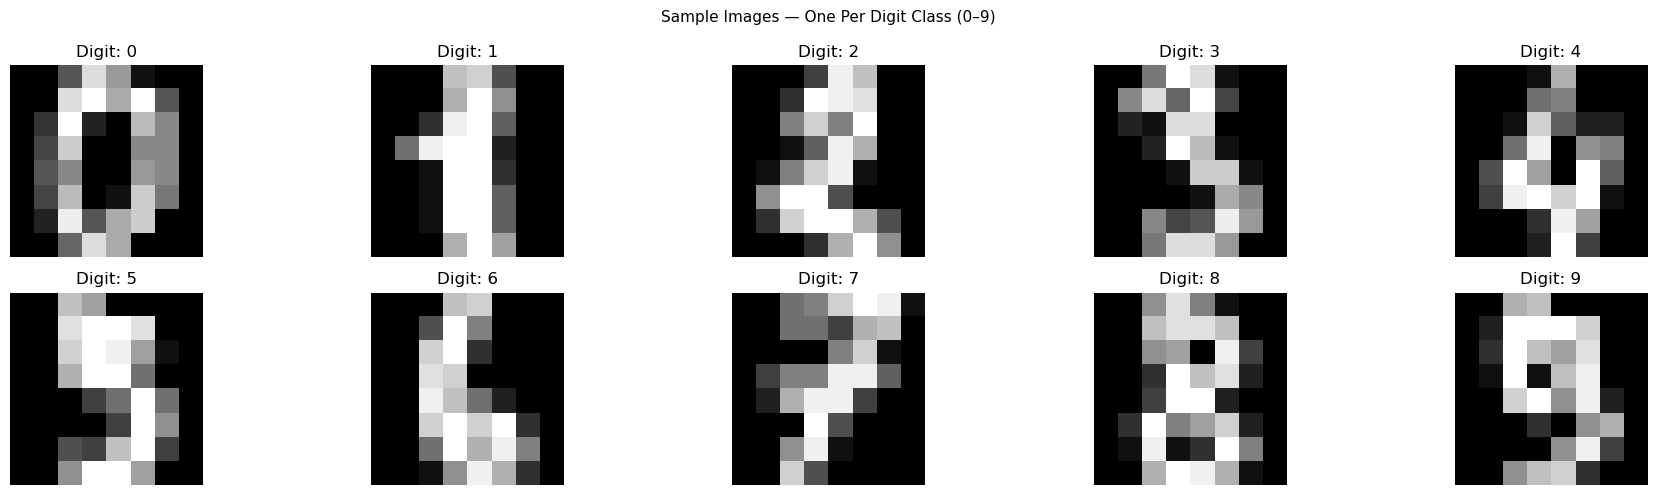

Each image is an 8x8 pixel grid. Darker pixels have higher intensity values.


In [3]:
# Show sample images for each digit class
fig, axes = plt.subplots(2, 5, figsize=(19, 5))
for digit, ax in enumerate(axes.flatten()):
    idx = np.where(y == digit)[0][0]
    ax.imshow(images[idx], cmap='gray')
    ax.set_title(f"Digit: {digit}")
    ax.axis('off')
plt.suptitle('Sample Images — One Per Digit Class (0–9)', fontsize=11)
plt.tight_layout()
plt.savefig('p3_sample_digits.png', dpi=100)
plt.show()
print("Each image is an 8x8 pixel grid. Darker pixels have higher intensity values.")

Samples per digit class:
0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180
Name: count, dtype: int64


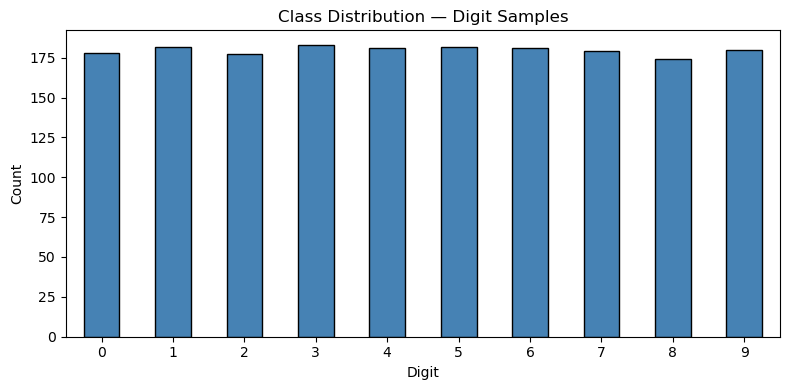

In [4]:
# Class distribution
class_counts = pd.Series(y).value_counts().sort_index()
print("Samples per digit class:")
print(class_counts)

plt.figure(figsize=(8,4))
class_counts.plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('Class Distribution — Digit Samples')
plt.xlabel('Digit')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('p3_class_dist.png', dpi=100)
plt.show()

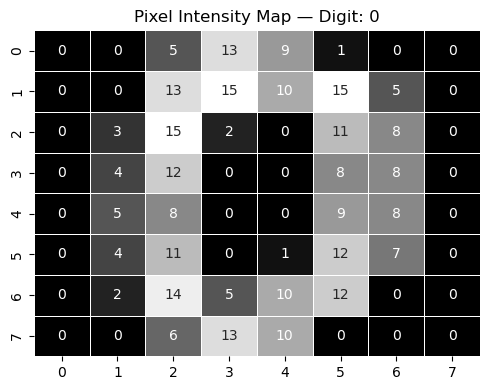

Each number represents the pixel intensity (0=black, 16=white)


In [7]:
# Pixel intensity heatmap for one sample
plt.figure(figsize=(5,4))
sample_image = images[0]
sns.heatmap(sample_image, cmap='gray', annot=True, fmt='.0f', linewidths=0.5, cbar=False)
plt.title(f'Pixel Intensity Map — Digit: {y[0]}')
plt.tight_layout()
plt.savefig('p3_pixel_heatmap.png', dpi=100)
plt.show()
print("Each number represents the pixel intensity (0=black, 16=white)")

## Step 3: Preprocessing
Images are already flattened into 64-feature vectors. We apply **StandardScaler** to normalize pixel intensities before training. This is important for Logistic Regression and SVM which are sensitive to feature scale.

In [5]:
# Step 4: Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print("Training samples:", X_train.shape)
print("Test samples:", X_test.shape)

Training samples: (1347, 64)
Test samples: (450, 64)


## Step 4: Model Training — Three Classifiers

In [6]:
# Step 5: Train Model A — Logistic Regression (with pipeline)
pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=3000, random_state=42))
])
pipe_lr.fit(X_train, y_train)
pred_lr = pipe_lr.predict(X_test)
acc_lr = accuracy_score(y_test, pred_lr)
print("Logistic Regression Accuracy:", round(acc_lr, 4))

Logistic Regression Accuracy: 0.9778


In [7]:
# Train Model B — Support Vector Machine
pipe_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(kernel='rbf', C=10, gamma=0.001, random_state=42))
])
pipe_svm.fit(X_train, y_train)
pred_svm = pipe_svm.predict(X_test)
acc_svm = accuracy_score(y_test, pred_svm)
print("SVM Accuracy:", round(acc_svm, 4))

SVM Accuracy: 0.9867


In [8]:
# Train Model C — Random Forest (no scaling needed)
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)
acc_rf = accuracy_score(y_test, pred_rf)
print("Random Forest Accuracy:", round(acc_rf, 4))

Random Forest Accuracy: 0.9667


## Step 5: Evaluation

In [9]:
# Step 6: Classification reports for all models
model_names = ['Logistic Regression', 'SVM', 'Random Forest']
preds = [pred_lr, pred_svm, pred_rf]
accs = [acc_lr, acc_svm, acc_rf]

for name, pred in zip(model_names, preds):
    print(f"=== {name} ===")
    print(classification_report(y_test, pred))
    print()

=== Logistic Regression ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        45
           1       0.93      0.93      0.93        46
           2       1.00      1.00      1.00        44
           3       1.00      1.00      1.00        46
           4       0.98      1.00      0.99        45
           5       1.00      0.98      0.99        46
           6       1.00      0.98      0.99        45
           7       0.98      1.00      0.99        45
           8       0.91      0.93      0.92        43
           9       0.98      0.96      0.97        45

    accuracy                           0.98       450
   macro avg       0.98      0.98      0.98       450
weighted avg       0.98      0.98      0.98       450


=== SVM ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        45
           1       0.94      0.98      0.96        46
           2       1.00      1.00    

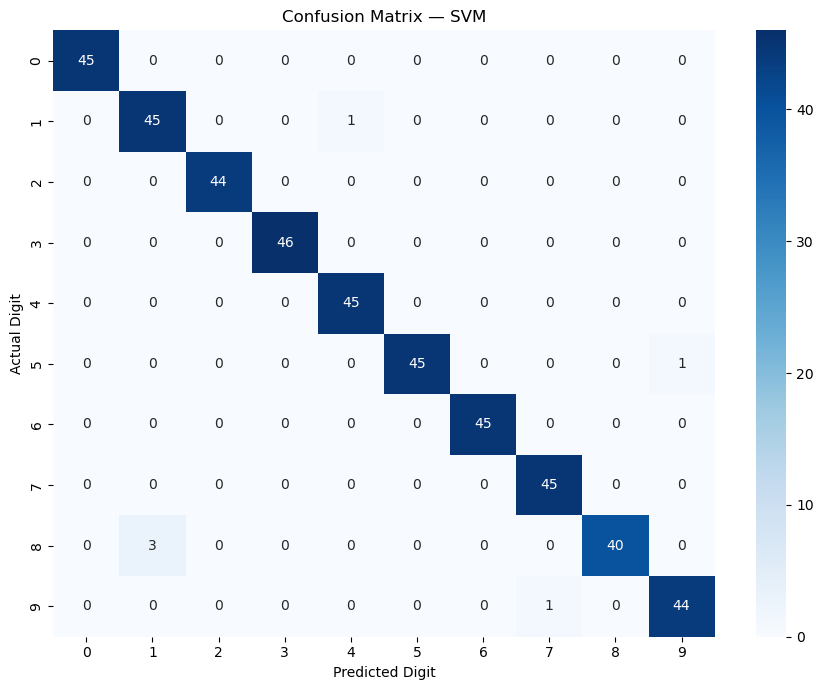

In [10]:
# Confusion matrix for best model (SVM usually best)
best_pred = pred_svm
best_name = 'SVM'

cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(9,7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(10), yticklabels=range(10))
plt.title(f'Confusion Matrix — {best_name}')
plt.xlabel('Predicted Digit')
plt.ylabel('Actual Digit')
plt.tight_layout()
plt.savefig('p3_confusion_matrix.png', dpi=100)
plt.show()

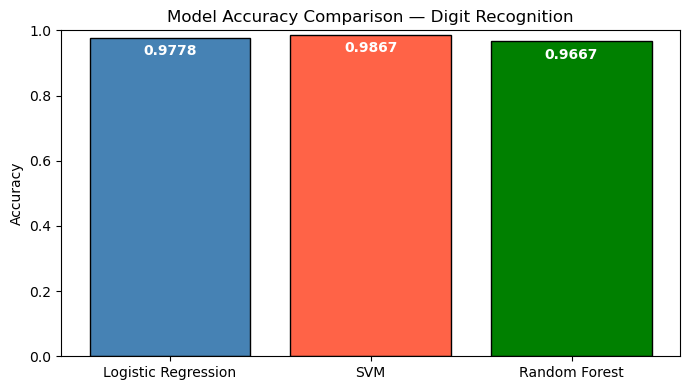

In [11]:
# Model accuracy comparison
plt.figure(figsize=(7,4))
bars = plt.bar(model_names, accs, color=['steelblue','tomato','green'], edgecolor='black')
for bar, acc in zip(bars, accs):
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()-0.02,
             f'{acc:.4f}', ha='center', va='top', color='white', fontweight='bold')
plt.ylim(0, 1)
plt.title('Model Accuracy Comparison — Digit Recognition')
plt.ylabel('Accuracy')
plt.tight_layout()
plt.savefig('p3_accuracy_compare.png', dpi=100)
plt.show()

Misclassified samples: 6 out of 450


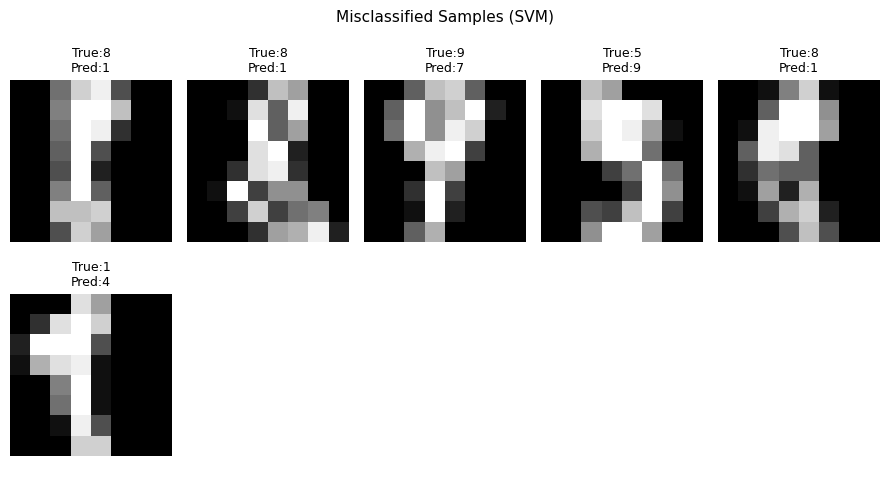

In [12]:
# Step 7: Error analysis — show some misclassified samples
best_model = pipe_svm
errors = np.where(best_pred != y_test)[0]
print(f"Misclassified samples: {len(errors)} out of {len(y_test)}")

if len(errors) > 0:
    show = min(10, len(errors))
    fig, axes = plt.subplots(2, 5, figsize=(9, 5))
    for i, ax in enumerate(axes.flatten()):
        if i < show:
            idx = errors[i]
            img = X_test[idx].reshape(8, 8)
            ax.imshow(img, cmap='gray')
            ax.set_title(f"True:{y_test[idx]}\nPred:{best_pred[idx]}", fontsize=9)
            ax.axis('off')
        else:
            ax.axis('off')
    plt.suptitle('Misclassified Samples (SVM)', fontsize=11)
    plt.tight_layout()
    plt.savefig('p3_errors.png', dpi=100)
    plt.show()

In [13]:
# Cross-validation score for best model
cv_scores = cross_val_score(pipe_svm, X, y, cv=5, scoring='accuracy')
print("5-Fold Cross-Validation Scores (SVM):", cv_scores.round(4))
print("Mean CV Accuracy:", round(cv_scores.mean(), 4))
print("Std Dev:", round(cv_scores.std(), 4))

5-Fold Cross-Validation Scores (SVM): [0.9472 0.9167 0.9582 0.9471 0.9304]
Mean CV Accuracy: 0.9399
Std Dev: 0.0146


## Step 6: Results Summary
| Model | Test Accuracy |
|---|---|
| Logistic Regression | See output |
| SVM (RBF kernel) | See output |
| Random Forest | See output |

**Best model:** SVM with RBF kernel typically achieves >97% accuracy on this dataset.  
**Key insight:** Digits 3, 8, and 9 are most commonly confused because of similar pixel patterns.

## Step 7: Responsible AI Report

### Fairness
- **Risk:** The digits dataset is from a relatively homogeneous writing style. A model trained here may perform worse on handwriting from people with motor disabilities, elderly users, or those writing in non-standard styles.
- **Mitigation:** Test on diverse handwriting samples. Report per-class accuracy. Avoid deploying without demographic testing.

### Privacy
- **Risk:** Handwriting can be biometrically linked to individuals. If real handwriting samples are collected, they become personal data.
- **Mitigation:** Use synthetic or aggregated datasets. Anonymize sources. Do not store raw handwriting linked to personal records.

### Explainability
- **What:** Confusion matrix reveals which digits are hardest to classify. Error analysis on misclassified samples helps identify failure patterns.
- **Limitation:** SVM predictions are hard to explain at the individual level. A Decision Tree would be more interpretable but less accurate.

### Accountability
- **Risk:** In high-stakes applications (e.g., cheque processing), a digit misread as 8 vs 3 could cause financial errors.
- **Mitigation:** Set a confidence threshold. Low-confidence predictions should be flagged for human review. Document the error rate publicly.

### Limitations
- Only 8×8 pixel images used. Real-world digits require higher resolution (MNIST: 28×28).
- No augmentation applied. Rotation or noise could reduce performance significantly.
- Model is not tested on handwriting outside the training distribution.